# Multivariable calculus 4: Lagrange multipliers

*Learning path: multivariable calculus, part 4 of 7.* [Index](README.md) · Previous: [Optimization](03-optimization.ipynb) · Next: [Multiple integrals](05-multiple-integrals.ipynb)

A walker on a circular path around a hill wants the highest point of the path, not of the hill. A factory wants the
most output for a fixed budget. These are optimization problems **with a constraint**: we may only move along a
curve (or a surface). Lagrange found a beautiful way to handle them, and it comes from one picture.

**Who this is for.** You know gradients and that they are perpendicular to level curves
([lesson 2](02-partial-derivatives-and-gradient.ipynb), section 4), and critical points ([lesson 3](03-optimization.ipynb)).

**What you will be able to do afterwards:**

1. explain, with a picture of level curves, why at a constrained extreme $\nabla f = \lambda \nabla g$;
2. set up and solve the Lagrange equations by hand for small problems;
3. use `lagrange` for bigger ones and read the multiplier $\lambda$ as a rate;
4. handle two constraints at once.

Plan about 45 minutes.

## 1. The picture

Find the largest value of $f(x, y) = xy$ on the circle $x^2 + y^2 = 2$. Draw the level curves of $f$ (hyperbolas)
and the circle:

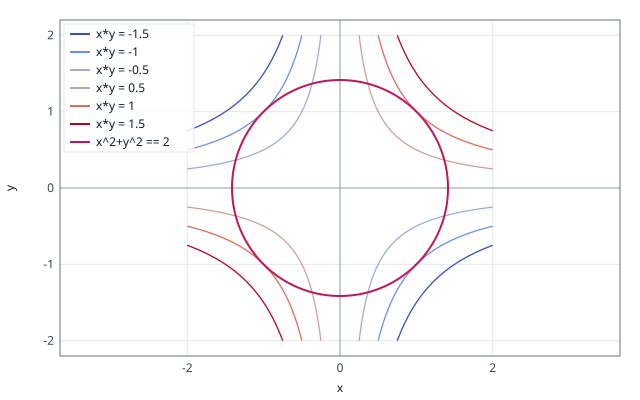

> `show`: Overlays plots: all 2D, or all 3D.

In [1]:
show(contour(x*y, x, -2, 2, y, -2, 2, [-1.5 -1 -0.5 0.5 1 1.5]), implicitplot(x^2 + y^2 == 2, x, -2, 2, y, -2, 2))

Walk along the circle and watch which level curves you cross. Where the circle **crosses** a level curve, you can
still go up by walking on. You can't go up any more where the circle only **touches** a level curve: at the
highest level you reach, $xy = 1$, at $(1, 1)$ and $(-1, -1)$. Touching curves have the same tangent line there,
so their normals are parallel. The normals are the gradients. So at a constrained extreme

$$\nabla f = \lambda\, \nabla g \qquad \text{and} \qquad g = 0,$$

for some number $\lambda$, the **Lagrange multiplier**. Here $g(x, y) = x^2 + y^2 - 2$.

**Try this.** On the picture, find the points where the circle touches the level curve $xy = -1$. What kind of
extreme are they?

## 2. Solving the equations by hand

For $f = xy$, $g = x^2 + y^2 - 2$:

$$y = 2\lambda x, \qquad x = 2\lambda y, \qquad x^2 + y^2 = 2.$$

Multiply the first by $y$ and the second by $x$: $y^2 = 2\lambda xy = x^2$. So $y = \pm x$, and the circle gives
$x^2 = 1$. Four points: $(1, 1)$ and $(-1, -1)$ with $f = 1$ (and $\lambda = \tfrac12$), $(1, -1)$ and $(-1, 1)$ with
$f = -1$ (and $\lambda = -\tfrac12$). The circle is closed and bounded, so $f$ does have a largest and a smallest value
on it, and they must be among these points: max $1$, min $-1$. Galileo agrees; its note lists $\lambda$ and $f$ at
every point:

In [2]:
lagrange(x*y, x^2 + y^2 == 2, [x y])

[-1, -1;
 -1,  1;
  1, -1;
  1,  1]

> At an extreme of f on the constraint, grad f is parallel to grad g: grad f = λ grad g, together with g = 0. Galileo solved y-2*lambda*x = 0, x-2*lambda*y = 0, x^2+y^2-2 = 0 and lists the points, one per row:
>
> - (-1, -1), lambda = 1/2: f = 1 (largest)
> - (-1, 1), lambda = -1/2: f = -1 (smallest)
> - (1, -1), lambda = -1/2: f = -1 (smallest)
> - (1, 1), lambda = 1/2: f = 1 (largest)
>
> On a closed and bounded constraint (a circle, an ellipse) the largest of these values is the maximum and the smallest the minimum. λ tells how fast the best value changes when the constraint is relaxed.

How to read the call: `lagrange(f, g, [x y])` with the constraint written as an equation (or as an expression $g$
meaning $g = 0$). It solves the system $\nabla f = \lambda \nabla g$, $g = 0$ exactly when it is polynomial, and
returns the points, one per row.

**Try this.** Find the largest and smallest value of $f = x + 2y$ on the circle $x^2 + y^2 = 5$ by hand. Then check
with `lagrange`. (You met the answer in lesson 1, section 5.)

## 3. The closest point

Which point of the circle $x^2 + y^2 = 1$ is closest to $(3, 4)$? Minimize the squared distance
$(x - 3)^2 + (y - 4)^2$ (the square root only gets in the way, and has its minimum at the same place):

In [3]:
lagrange((x - 3)^2 + (y - 4)^2, x^2 + y^2 - 1, [x y])

[-3/5, -4/5;
  3/5,  4/5]

> At an extreme of f on the constraint, grad f is parallel to grad g: grad f = λ grad g, together with g = 0. Galileo solved 2*(x-lambda*x-3) = 0, 2*(y-lambda*y-4) = 0, x^2+y^2-1 = 0 and lists the points, one per row:
>
> - (-3/5, -4/5), lambda = 6: f = 36 (largest)
> - (3/5, 4/5), lambda = -4: f = 16 (smallest)
>
> On a closed and bounded constraint (a circle, an ellipse) the largest of these values is the maximum and the smallest the minimum. λ tells how fast the best value changes when the constraint is relaxed.

Two points: $(\tfrac35, \tfrac45)$ is the closest (distance $4$), $(-\tfrac35, -\tfrac45)$ the farthest (distance 6).
Both lie on the line through the origin and $(3, 4)$, as geometry says they should: the shortest path to a circle
heads straight for the center.

## 4. What λ means

Change the constraint a little: $g(x, y) = c$ instead of $0$. Then the best value $f^*$ changes too, and Lagrange's
multiplier is the rate:

$$\lambda = \frac{d f^*}{d c}.$$

Economists call it the **shadow price**: how much more profit one more unit of budget would bring. Check it on the
first example with the circle $x^2 + y^2 = c$: the best point is $x = y = \sqrt{c/2}$, so $f^* = c/2$ and
$df^*/dc = \tfrac12$, which is the $\lambda$ Galileo reported at the maximum.

**Try this.** In section 3, write the constraint as $x^2 + y^2 = c$. The closest distance squared is
$(5 - \sqrt c)^2$. Differentiate at $c = 1$ and compare with $\lambda$ from the note at the closest point.

## 5. A box with the most volume

A box without a lid is made from 12 m² of cardboard. Which box holds the most? Volume $V = xyz$, area of the base and
four sides $xy + 2yz + 2xz = 12$:

In [4]:
lagrange(x*y*z, x*y + 2*y*z + 2*x*z == 12, [x y z])

[-2, -2, -1;
  2,  2,  1]

> At an extreme of f on the constraint, grad f is parallel to grad g: grad f = λ grad g, together with g = 0. Galileo solved y*z-lambda*(y+2*z) = 0, x*z-lambda*(x+2*z) = 0, x*y-lambda*(2*x+2*y) = 0, x*y+2*x*z+2*y*z-12 = 0 and lists the points, one per row:
>
> - (-2, -2, -1), lambda = -1/2: f = -4 (smallest)
> - (2, 2, 1), lambda = 1/2: f = 4 (largest)
>
> On a closed and bounded constraint (a circle, an ellipse) the largest of these values is the maximum and the smallest the minimum. λ tells how fast the best value changes when the constraint is relaxed.

The rows with negative sides are mathematically valid but not boxes. The box is $2 \times 2 \times 1$ m, volume 4 m³:
a square base and half as high, because the lid is missing. By hand, the trick is to multiply the three equations
$yz = \lambda(y + 2z)$, $xz = \lambda(x + 2z)$, $xy = \lambda(2x + 2y)$ by $x$, $y$, $z$; the left sides are all $xyz$.

## 6. Two constraints

On a curve in space we have two constraints, $g_1 = 0$ and $g_2 = 0$. The rule becomes
$\nabla f = \lambda_1 \nabla g_1 + \lambda_2 \nabla g_2$. Example: the point of the line where the planes $x + y + z = 1$
and $x - y = 0$ meet that is closest to the origin:

In [5]:
lagrange(x^2 + y^2 + z^2, [x + y + z - 1, x - y], [x y z])

[1/3, 1/3, 1/3]

> At an extreme of f on the constraint, grad f is parallel to grad g: grad f = λ grad g, together with g = 0. Galileo solved 2*x-lambda1-lambda2 = 0, lambda2-lambda1+2*y = 0, 2*z-lambda1 = 0, x+y+z-1 = 0, x-y = 0 and lists the points, one per row:
>
> - (1/3, 1/3, 1/3), lambda1 = 2/3, lambda2 = 0: f = 1/3
>
> On a closed and bounded constraint (a circle, an ellipse) the largest of these values is the maximum and the smallest the minimum. λ tells how fast the best value changes when the constraint is relaxed.

$(\tfrac13, \tfrac13, \tfrac13)$. Give a list of constraints, and the note names the multipliers `lambda1`,
`lambda2`.

## Exercises

1. **Rectangle in an ellipse.** Find the largest rectangle (sides parallel to the axes) inside the ellipse
   $x^2/4 + y^2 = 1$. Maximize $4xy$; check your answer with `lagrange` and draw the ellipse and the rectangle.
2. **Hottest point.** The temperature on the unit circle is $T = 4x^2 + 2y^2 - 2y$. Find the hottest and coldest
   points, by hand and with `lagrange`.
3. **Shadow price.** Maximize $f = x^{1/2} y^{1/2}$ (production) subject to $2x + y = 100$ (budget). Use
   $\ln f$ or $f^2$ to make the equations polynomial; why is that allowed? Then estimate how much more production
   one extra unit of budget buys.
4. **Distance to a curve.** Find the points of the hyperbola $xy = 1$ closest to the origin. Draw the level circles
   $x^2 + y^2 = c$ and the hyperbola to see the touching.
5. **When it fails.** Minimize $f = x$ on the curve $y^2 = x^3$. The answer is the origin, but show that the
   Lagrange equations have no solution there. What goes wrong? (Look at $\nabla g$ at the origin.)

## Hints and answers

* **Section 1, Try this.** $(1, -1)$ and $(-1, 1)$: the minimum value $-1$ on the circle.
* **Section 2, Try this.** $1 = 2\lambda x$, $2 = 2\lambda y$ give $y = 2x$; then $5x^2 = 5$. Max $5$ at $(1, 2)$, min
  $-5$ at $(-1, -2)$.
* **Section 4, Try this.** $\frac{d}{dc}(5 - \sqrt c)^2 = -(5 - \sqrt c)/\sqrt c = -4$ at $c = 1$: the note gives
  $\lambda = -4$ at $(\tfrac35, \tfrac45)$.
* **Exercise 1.** $x = \sqrt 2$, $y = 1/\sqrt 2$, area $4xy = 4$.
* **Exercise 2.** On the circle $T = 4 - 2y^2 - 2y$. Hottest $T = 4.5$ at $(\pm\sqrt{3}/2, -1/2)$; coldest $T = 0$ at $(0, 1)$. (At $(0, -1)$, $T = 4$.)
* **Exercise 3.** Maximizing $f^2 = xy$ gives the same point, because squaring is increasing for $f \ge 0$:
  $x = 25$, $y = 50$, $f = \sqrt{1250} \approx 35.4$. With the budget as $c$, $f^* = c/(2\sqrt 2)$, so one more unit
  of budget buys about $0.354$ more production.
* **Exercise 4.** $(1, 1)$ and $(-1, -1)$, distance $\sqrt 2$.
* **Exercise 5.** $\nabla g = [-3x^2, 2y] = [0, 0]$ at the origin (the curve has a cusp there), so it can't be parallel
  to $\nabla f = [1, 0]$. Lagrange's rule assumes $\nabla g \ne 0$ on the constraint; check such points separately.

## Sources

1. J.-L. Lagrange, *Mécanique analytique*, Paris (1788). The method appears for mechanics with constraints.
2. J. Stewart, *Calculus: Early Transcendentals*, 9th ed., Cengage (2020), section 14.8.
3. G. Strang and E. Herman, *Calculus Volume 3*, OpenStax (2016), section 4.8.
4. D. P. Bertsekas, *Constrained Optimization and Lagrange Multiplier Methods*, Athena Scientific (1996), for the
   meaning of the multipliers.